In [1]:
#Step 1: Import Libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import f_oneway

sns.set_style("whitegrid")

print("Libraries imported successfully.")



Libraries imported successfully.


In [2]:
#Step 2: Load All 9 Datasets from GitHub

import pandas as pd

url = 'https://raw.githubusercontent.com/Ravna95/Capstone-Project/main/'
base_url = 'https://raw.githubusercontent.com/Ravna95/Capstone-Project/main/'

customers = pd.read_csv(base_url + "Customers.csv")
orders = pd.read_csv(base_url + "Orders.csv")
order_items = pd.read_csv(base_url + "Order%20Items.csv")
products = pd.read_csv(base_url + "Products.csv")
categories = pd.read_csv(base_url + "Categories.csv")
departments = pd.read_csv(base_url + "Departments.csv")
shipping = pd.read_csv(base_url + "Shipping.csv")
geography = pd.read_csv(base_url + "Geography.csv")
payment_types = pd.read_csv(base_url + "Payment%20Types.csv")

print("All datasets loaded successfully.")



All datasets loaded successfully.


In [3]:
#Step 3: Explore Dataset Sizes

datasets = {
    "Customers": customers,
    "Orders": orders,
    "Order Items": order_items,
    "Products": products,
    "Categories": categories,
    "Departments": departments,
    "Shipping": shipping,
    "Geography": geography,
    "Payment Types": payment_types
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")


Customers: (20652, 11)
Orders: (65752, 11)
Order Items: (180519, 15)
Products: (118, 7)
Categories: (51, 3)
Departments: (11, 2)
Shipping: (65752, 3)
Geography: (64990, 9)
Payment Types: (4, 2)


In [4]:
#Step 4: Check Column Names

for name, df in datasets.items():
    print("n" + "="*60)
    print(name)
    print("="*60)

    print(df.columns.tolist())

n============================================================
Customers
['Customer Id', 'Customer Fname', 'Customer Lname', 'Customer Email', 'Customer Password', 'Customer Segment', 'Customer Street', 'Customer City', 'Customer State', 'Customer Country', 'Customer Zipcode']
n============================================================
Orders
['Order Id', 'Order Customer Id', 'Payment_Type_ID', 'Shipment_Id', 'Location_Id', 'order date (DateOrders)', 'Order Status', 'Delivery Status', 'Late_delivery_risk', 'Days for shipping (real)', 'Days for shipment (scheduled)']
n============================================================
Order Items
['Order Item Id', 'Order Id', 'Order Item Cardprod Id', 'Product Card Id', 'Customer Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Order Item Total', 'Sales', 'Sales per customer', 'Benefit per order', 'Order Profit Per Order']
n==================================

In [5]:
#Step 5: Check Missing Values

for name, df in datasets.items():
    print("n" + "="*60)
    print(name)
    print("="*60)

    print(df.isnull().sum())

n============================================================
Customers
Customer Id          0
Customer Fname       0
Customer Lname       8
Customer Email       0
Customer Password    0
Customer Segment     0
Customer Street      0
Customer City        0
Customer State       0
Customer Country     0
Customer Zipcode     3
dtype: int64
n============================================================
Orders
Order Id                         0
Order Customer Id                0
Payment_Type_ID                  0
Shipment_Id                      0
Location_Id                      0
order date (DateOrders)          0
Order Status                     0
Delivery Status                  0
Late_delivery_risk               0
Days for shipping (real)         0
Days for shipment (scheduled)    0
dtype: int64
n============================================================
Order Items
Order Item Id               0
Order Id                    0
Order Item Cardprod Id      0
Product Card Id             0
C

In [6]:
#Step 6: Check Duplicate Records
for name, df in datasets.items():
    print(
        f"{name}: {df.duplicated().sum()} duplicate rows"
    )


Customers: 0 duplicate rows
Orders: 0 duplicate rows
Order Items: 0 duplicate rows
Products: 0 duplicate rows
Categories: 0 duplicate rows
Departments: 0 duplicate rows
Shipping: 0 duplicate rows
Geography: 0 duplicate rows
Payment Types: 0 duplicate rows


In [7]:
#this was inserted from Master Phyton notebook#
import os
import pandas as pd

# --- STEP 1: Verify Current Directory & Files ---
print('Current Working Directory:', os.getcwd())
print('Files available in folder:', os.listdir('.'))


# --- STEP 2: Handle Missing Values ---
# Products: Fill missing descriptions
products['Product Description'] = products['Product Description'].fillna(
    'No Description'
)

# Customers: Fill missing zipcodes
customers['Customer Zipcode'] = customers['Customer Zipcode'].fillna(0)

# Geography: Fill missing zipcodes and states
geography['Order Zipcode'] = geography['Order Zipcode'].fillna(0)
geography['Order State'] = geography['Order State'].fillna('Unknown')

# --- STEP 3: Merge All Datasets into One Master DataFrame ---
print('\nMerging datasets...')
master = order_items.merge(orders, on='Order Id', how='left', suffixes=('', '_order'))
master = master.merge(shipping, on='Shipment_Id', how='left')
master = master.merge(payment_types, on='Payment_Type_ID', how='left')
master = master.merge(geography, on='Location_Id', how='left')
master = master.merge(
    customers,
    left_on='Order Customer Id',
    right_on='Customer Id',
    how='left',
    suffixes=('', '_cust'),
)
master = master.merge(products, on='Product Card Id', how='left')
master = master.merge(
    categories, left_on='Product Category Id', right_on='Category Id', how='left'
)
master = master.merge(departments, on='Department Id', how='left')

# --- STEP 4: Save and Verify Final Dataset ---
master.to_csv('master_supply_chain.csv', index=False)
print('\nSuccess! master_supply_chain.csv has been created and saved.')

# Load back to check
df = pd.read_csv('master_supply_chain.csv')
print(f'Final Master Dataset Shape: {df.shape}')
print('\nFirst 3 rows preview:')
print(df.head(3))

Current Working Directory: /content
Files available in folder: ['.config', 'sample_data']

Merging datasets...

Success! master_supply_chain.csv has been created and saved.
Final Master Dataset Shape: (180519, 57)

First 3 rows preview:
   Order Item Id  Order Id  Order Item Cardprod Id  Product Card Id  \
0         180517     77202                    1360             1360   
1         179254     75939                    1360             1360   
2         179253     75938                    1360             1360   

   Customer Id  Order Item Discount  Order Item Discount Rate  \
0        20755            13.110000                      0.04   
1        19492            16.389999                      0.05   
2        19491            18.030001                      0.06   

   Order Item Product Price  Order Item Profit Ratio  Order Item Quantity  \
0                    327.75                     0.29                    1   
1                    327.75                    -0.80           

In [8]:
import numpy as np
import pandas as pd

print("Starting Step 7: Data Cleaning & Step 8: Feature Engineering...")

# ==========================================
# STEP 7: DATA CLEANING & PREPROCESSING
# ==========================================

# 7.1 Handle Missing Values in Products
if 'Product Description' in products.columns:
    products['Product Description'] = products['Product Description'].fillna('No Description Available')

# 7.2 Convert Date Columns to Datetime Objects (Using exact column name from Orders.csv)
if 'order date (DateOrders)' in orders.columns:
    orders['order_date'] = pd.to_datetime(orders['order date (DateOrders)'], errors='coerce')

if 'shipping date (DateOrders)' in shipping.columns:
    shipping['shipping_date'] = pd.to_datetime(shipping['shipping date (DateOrders)'], errors='coerce')

print("Data cleaning completed: Dates parsed and missing descriptions handled.")

# ==========================================
# STEP 8: FEATURE ENGINEERING & INTEGRATION
# ==========================================

# 8.1 Merge core tables to create a unified master dataframe for analysis
df = order_items.merge(
    orders[[
        'Order Id',
        'Order Customer Id',
        'Payment_Type_ID',
        'Shipment_Id',
        'Location_Id',
        'order_date',
        'Order Status',
        'Delivery Status',
        'Late_delivery_risk',
        'Days for shipping (real)',
        'Days for shipment (scheduled)'
    ]],
    on='Order Id',
    how='left'
)

df = df.merge(
    shipping[['Shipment_Id', 'Shipping Mode']],
    on='Shipment_Id',
    how='left'
)

df = df.merge(
    products[['Product Card Id', 'Product Category Id', 'Product Name', 'Product Price']],
    on='Product Card Id',
    how='left'
)

df = df.merge(
    categories[['Category Id', 'Category Name', 'Department Id']],
    left_on='Product Category Id',
    right_on='Category Id',
    how='left'
)

df = df.merge(departments, on='Department Id', how='left')

df = df.merge(
    customers[[
        'Customer Id',
        'Customer Segment',
        'Customer City',
        'Customer State',
        'Customer Country'
    ]],
    on='Customer Id',
    how='left'
)

df = df.merge(geography, on='Location_Id', how='left')
df = df.merge(payment_types, on='Payment_Type_ID', how='left')

# 8.2 Extract Temporal Features
df['Year'] = df['order_date'].dt.year
df['Month'] = df['order_date'].dt.month
df['DayOfWeek'] = df['order_date'].dt.day_name()
df['YearMonth'] = df['order_date'].dt.to_period('M').astype(str)
df['Quarter'] = df['order_date'].dt.quarter

# 8.3 Feature Engineering: Supply Chain & Profitability Metrics
df['Shipping_Delay_Variance'] = df['Days for shipping (real)'] - df['Days for shipment (scheduled)']

# Binary flag for profit/loss per line item (Option 3 Focus)
df['Is_Profitable'] = df['Order Profit Per Order'].apply(lambda x: 1 if x > 0 else 0)

print("Feature engineering completed: Temporal, shipping variance, and profitability flags added.")
print(f"Master Analysis DataFrame Shape: {df.shape}")
print(df[['order_date', 'Year', 'Month', 'YearMonth', 'Shipping_Delay_Variance']].head(3))


Starting Step 7: Data Cleaning & Step 8: Feature Engineering...
Data cleaning completed: Dates parsed and missing descriptions handled.
Feature engineering completed: Temporal, shipping variance, and profitability flags added.
Master Analysis DataFrame Shape: (180519, 53)
           order_date  Year  Month YearMonth  Shipping_Delay_Variance
0 2018-01-31 22:56:00  2018      1   2018-01                       -1
1 2018-01-13 12:27:00  2018      1   2018-01                        1
2 2018-01-13 12:06:00  2018      1   2018-01                        0


OBJECTIVE 1: EXECUTIVE SUMMARY METRICS
Total Sales Revenue      : $36,784,735.01
Total Net Profit         : $3,966,902.97
Overall Profit Margin    : 10.78%
Total Unique Orders      : 65,752


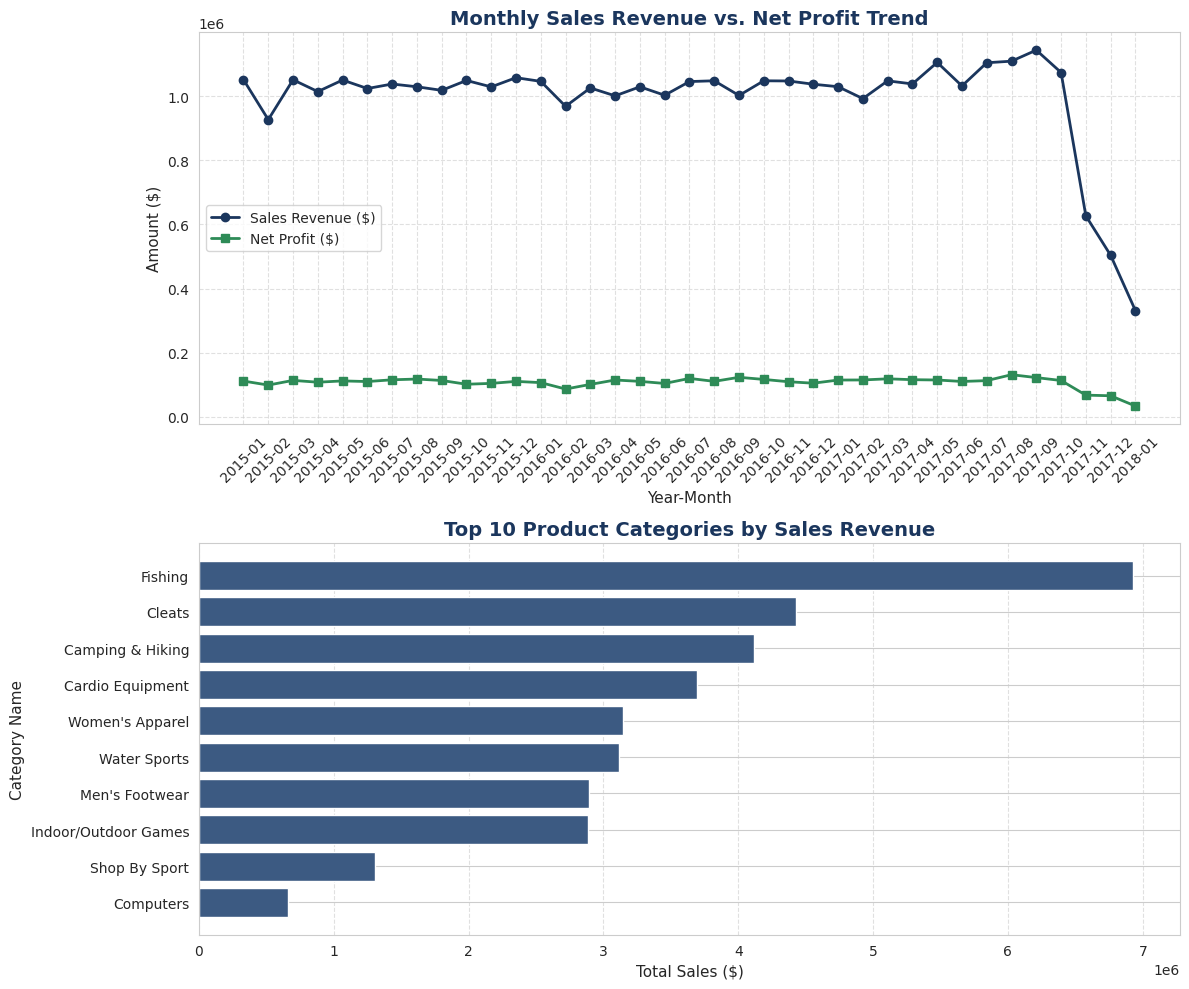


Visuals saved successfully to 'images/objective_1_sales_performance.png'.


In [9]:
# ==========================================
# OBJECTIVE 1: ANALYSE OVERALL SALES PERFORMANCE
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Ensure visualizations directory exists
import os
os.makedirs('images', exist_ok=True)

# 1. Calculate Key Sales Metrics
total_sales = df['Sales'].sum()
total_profit = df['Order Profit Per Order'].sum()
overall_profit_margin = (total_profit / total_sales) * 100
total_orders = df['Order Id'].nunique()

print("="*50)
print("OBJECTIVE 1: EXECUTIVE SUMMARY METRICS")
print("="*50)
print(f"Total Sales Revenue      : ${total_sales:,.2f}")
print(f"Total Net Profit         : ${total_profit:,.2f}")
print(f"Overall Profit Margin    : {overall_profit_margin:.2f}%")
print(f"Total Unique Orders      : {total_orders:,}")

# 2. Monthly Trend Aggregation
monthly_perf = df.groupby('YearMonth').agg(
    Monthly_Sales=('Sales', 'sum'),
    Monthly_Profit=('Order Profit Per Order', 'sum')
).reset_index()

# 3. Top Categories Aggregation
top_categories = df.groupby('Category Name').agg(
    Total_Sales=('Sales', 'sum')
).sort_values(by='Total_Sales', ascending=False).head(10).reset_index()

# ==========================================
# GENERATE RECOMMENDED VISUALIZATIONS
# ==========================================
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# Visual A: Line Chart - Monthly Sales Revenue vs Net Profit
axes[0].plot(monthly_perf['YearMonth'], monthly_perf['Monthly_Sales'], marker='o', color='#1B365D', linewidth=2, label='Sales Revenue ($)')
axes[0].plot(monthly_perf['YearMonth'], monthly_perf['Monthly_Profit'], marker='s', color='#2E8B57', linewidth=2, label='Net Profit ($)')
axes[0].set_title('Monthly Sales Revenue vs. Net Profit Trend', fontsize=14, fontweight='bold', color='#1B365D')
axes[0].set_xlabel('Year-Month', fontsize=11)
axes[0].set_ylabel('Amount ($)', fontsize=11)
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

# Visual B: Bar Chart - Top 10 Product Categories by Sales
top_categories_sorted = top_categories.sort_values(by='Total_Sales', ascending=True)
axes[1].barh(top_categories_sorted['Category Name'], top_categories_sorted['Total_Sales'], color='#3C5A82')
axes[1].set_title('Top 10 Product Categories by Sales Revenue', fontsize=14, fontweight='bold', color='#1B365D')
axes[1].set_xlabel('Total Sales ($)', fontsize=11)
axes[1].set_ylabel('Category Name', fontsize=11)
axes[1].grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('images/objective_1_sales_performance.png', dpi=300)
plt.show()

print("\nVisuals saved successfully to 'images/objective_1_sales_performance.png'.")

OBJECTIVE 2: SHIPPING MODE PERFORMANCE SUMMARY
 Shipping Mode  Avg_Actual_Days  Avg_Scheduled_Days  Avg_Delay_Variance  Late_Risk_Rate
   First Class         2.000000                 1.0            1.000000       95.267388
      Same Day         0.483618                 0.0            0.483618       46.149538
  Second Class         4.001565                 2.0            2.001565       76.717796
Standard Class         3.996898                 4.0           -0.003102       38.131930


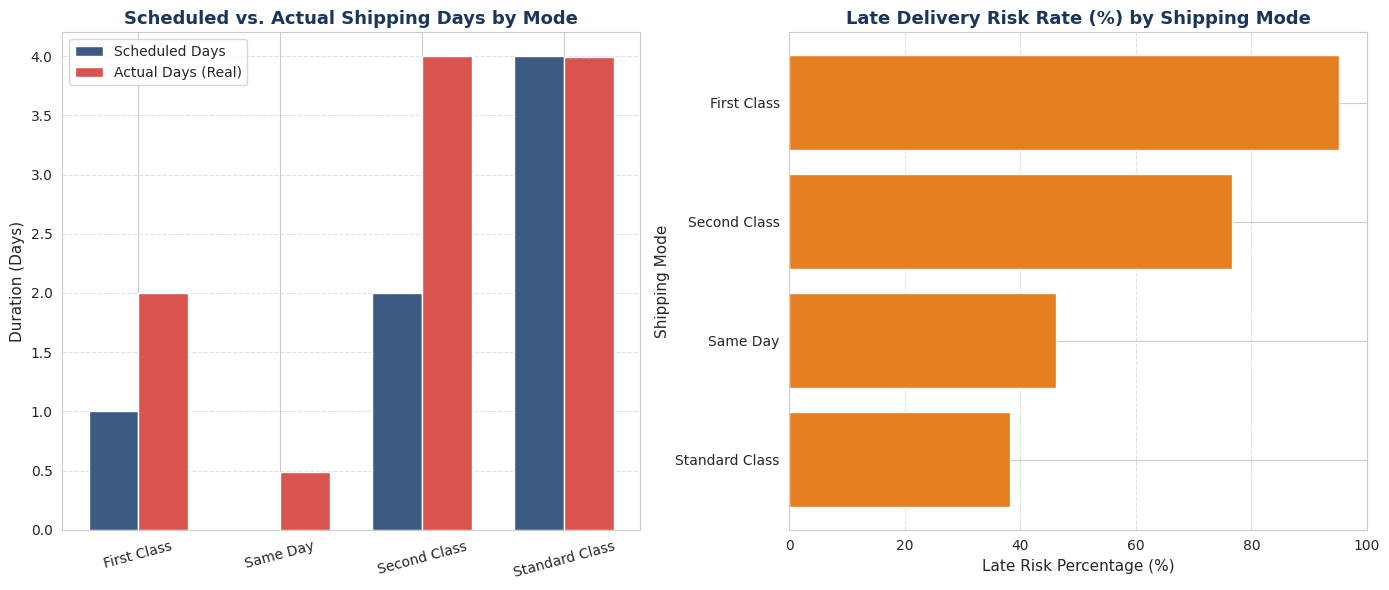


Visuals saved successfully to 'images/objective_2_shipping_performance.png'.


In [10]:
# ==========================================
# OBJECTIVE 2: SHIPPING MODE PERFORMANCE & FULFILLMENT EFFICIENCY
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Ensure visualizations directory exists
import os
os.makedirs('images', exist_ok=True)

# 1. Prepare Shipping & Orders Data
df_ship = orders.merge(shipping, on='Shipment_Id', how='left')
df_ship['Delay_Days'] = df_ship['Days for shipping (real)'] - df_ship['Days for shipment (scheduled)']

# 2. Aggregate Metrics by Shipping Mode
shipping_perf = df_ship.groupby('Shipping Mode').agg(
    Avg_Actual_Days=('Days for shipping (real)', 'mean'),
    Avg_Scheduled_Days=('Days for shipment (scheduled)', 'mean'),
    Avg_Delay_Variance=('Delay_Days', 'mean'),
    Late_Risk_Rate=('Late_delivery_risk', lambda x: x.mean() * 100)
).reset_index()

print("="*60)
print("OBJECTIVE 2: SHIPPING MODE PERFORMANCE SUMMARY")
print("="*60)
print(shipping_perf.to_string(index=False))

# ==========================================
# GENERATE RECOMMENDED VISUALIZATIONS
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Visual A: Grouped Bar Chart - Actual vs. Scheduled Shipping Days
x = np.arange(len(shipping_perf['Shipping Mode']))
width = 0.35

axes[0].bar(x - width/2, shipping_perf['Avg_Scheduled_Days'], width, label='Scheduled Days', color='#3C5A82')
axes[0].bar(x + width/2, shipping_perf['Avg_Actual_Days'], width, label='Actual Days (Real)', color='#D9534F')
axes[0].set_title('Scheduled vs. Actual Shipping Days by Mode', fontsize=13, fontweight='bold', color='#1B365D')
axes[0].set_xticks(x)
axes[0].set_xticklabels(shipping_perf['Shipping Mode'], rotation=15)
axes[0].set_ylabel('Duration (Days)', fontsize=11)
axes[0].legend()
axes[0].grid(axis='y', linestyle='--', alpha=0.6)

# Visual B: Horizontal Bar Chart - Late Delivery Risk / Variance Rate
shipping_perf_sorted = shipping_perf.sort_values(by='Late_Risk_Rate', ascending=True)
axes[1].barh(shipping_perf_sorted['Shipping Mode'], shipping_perf_sorted['Late_Risk_Rate'], color='#E67E22')
axes[1].set_title('Late Delivery Risk Rate (%) by Shipping Mode', fontsize=13, fontweight='bold', color='#1B365D')
axes[1].set_xlabel('Late Risk Percentage (%)', fontsize=11)
axes[1].set_ylabel('Shipping Mode', fontsize=11)
axes[1].grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('images/objective_2_shipping_performance.png', dpi=300)
plt.show()

print("\nVisuals saved successfully to 'images/objective_2_shipping_performance.png'.")

DEPARTMENT PROFITABILITY SUMMARY
   Department Name  Total_Sales  Total_Profit  Avg_Discount_Rate  Profit_Margin_%
           Apparel 7.976255e+06  8.818829e+05           0.101656        11.056353
         Book Shop 1.258740e+04  8.830100e+02           0.102296         7.015031
        Discs Shop 2.288877e+05  2.419312e+04           0.101826        10.569863
          Fan Shop 1.711387e+07  1.834155e+06           0.101647        10.717362
           Fitness 3.970509e+05  4.653806e+04           0.101593        11.720931
          Footwear 4.006499e+06  4.102225e+05           0.101661        10.238927
              Golf 4.609028e+06  4.975236e+05           0.101577        10.794544
Health and Beauty  1.060805e+05  9.493630e+03           0.101354         8.949460
          Outdoors 1.253351e+06  1.452515e+05           0.102148        11.589045
          Pet Shop 4.152480e+04  3.589260e+03           0.101585         8.643654
        Technology 1.039599e+06  1.131700e+05           0.101816 

/tmp/ipykernel_2901/3002731284.py:51: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  discount_impact = df.groupby('Discount_Bin')['Order Profit Per Order'].mean().reset_index()


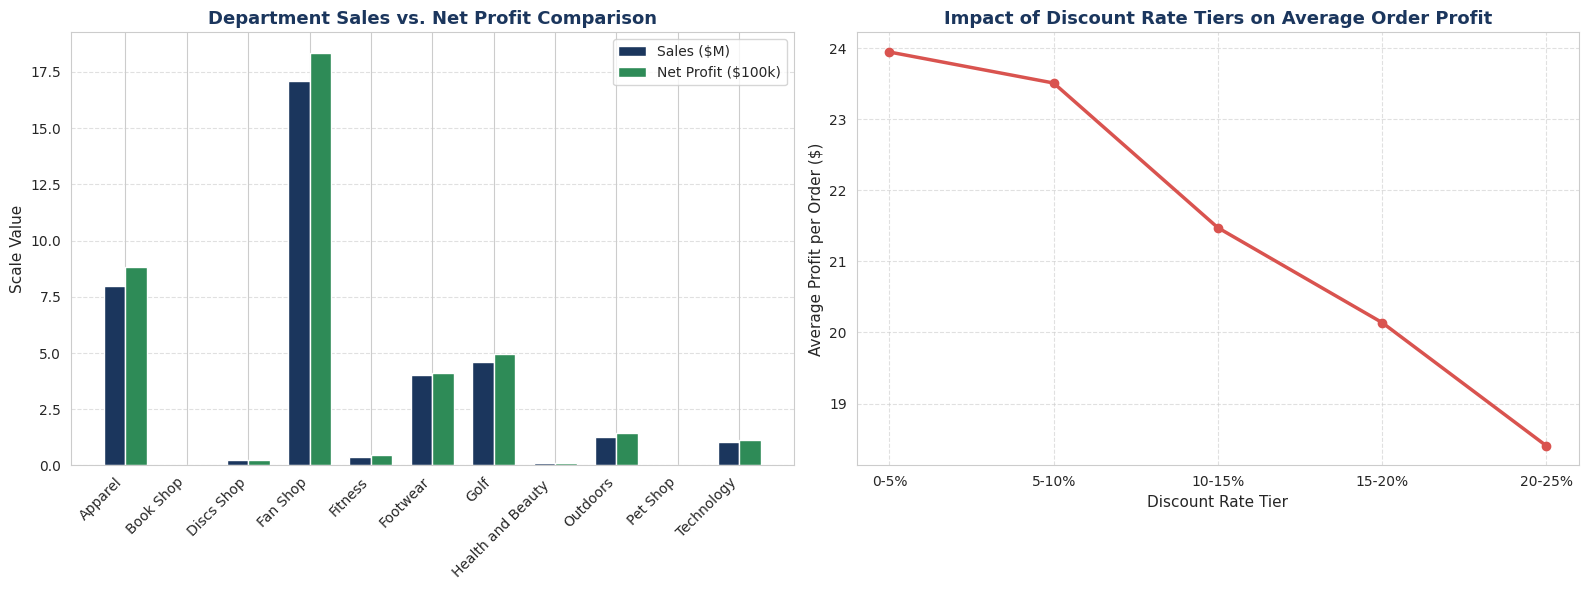


Visuals saved successfully to 'images/objective_3_profitability.png'.


In [11]:
# ==========================================
# OBJECTIVE 3: PRODUCT, CATEGORY & DEPARTMENT PROFITABILITY
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Ensure visualizations directory exists
import os
os.makedirs('images', exist_ok=True)

# 1. Department Profitability Aggregation
dept_perf = df.groupby('Department Name').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Order Profit Per Order', 'sum'),
    Avg_Discount_Rate=('Order Item Discount Rate', 'mean')
).reset_index()
dept_perf['Profit_Margin_%'] = (dept_perf['Total_Profit'] / dept_perf['Total_Sales']) * 100

print("="*60)
print("DEPARTMENT PROFITABILITY SUMMARY")
print("="*60)
print(dept_perf.to_string(index=False))

# ==========================================
# GENERATE RECOMMENDED VISUALIZATIONS
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Visual A: Clustered Bar Chart - Department Sales vs. Net Profit
x = np.arange(len(dept_perf['Department Name']))
width = 0.35

sales_scaled = dept_perf['Total_Sales'] / 1e6  # in Millions
profit_scaled = dept_perf['Total_Profit'] / 1e5 # in 100k for scaling

axes[0].bar(x - width/2, sales_scaled, width, label='Sales ($M)', color='#1B365D')
axes[0].bar(x + width/2, profit_scaled, width, label='Net Profit ($100k)', color='#2E8B57')
axes[0].set_title('Department Sales vs. Net Profit Comparison', fontsize=13, fontweight='bold', color='#1B365D')
axes[0].set_xticks(x)
axes[0].set_xticklabels(dept_perf['Department Name'], rotation=45, ha='right')
axes[0].set_ylabel('Scale Value', fontsize=11)
axes[0].legend()
axes[0].grid(axis='y', linestyle='--', alpha=0.6)

# Visual B: Scatter / Line Plot - Discount Impact on Profit Margin
# Group by discount rate bins to show margin erosion
df['Discount_Bin'] = pd.cut(df['Order Item Discount Rate'], bins=5, labels=['0-5%', '5-10%', '10-15%', '15-20%', '20-25%'])
discount_impact = df.groupby('Discount_Bin')['Order Profit Per Order'].mean().reset_index()

axes[1].plot(discount_impact['Discount_Bin'], discount_impact['Order Profit Per Order'], marker='o', color='#D9534F', linewidth=2.5)
axes[1].set_title('Impact of Discount Rate Tiers on Average Order Profit', fontsize=13, fontweight='bold', color='#1B365D')
axes[1].set_xlabel('Discount Rate Tier', fontsize=11)
axes[1].set_ylabel('Average Profit per Order ($)', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('images/objective_3_profitability.png', dpi=300)
plt.show()

print("\nVisuals saved successfully to 'images/objective_3_profitability.png'.")

Datasets loaded successfully!

Orders columns: ['Order Id', 'Order Customer Id', 'Payment_Type_ID', 'Shipment_Id', 'Location_Id', 'order date (DateOrders)', 'Order Status', 'Delivery Status', 'Late_delivery_risk', 'Days for shipping (real)', 'Days for shipment (scheduled)']
Order Items columns: ['Order Item Id', 'Order Id', 'Order Item Cardprod Id', 'Product Card Id', 'Customer Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Order Item Total', 'Sales', 'Sales per customer', 'Benefit per order', 'Order Profit Per Order']
Shipping columns: ['Shipping Mode', 'shipping date (DateOrders)', 'Shipment_Id']

Merged dataset created!
Total records: 180519

SHIPPING MODE PROFITABILITY ANALYSIS
 Shipping Mode  Total_Sales  Total_Profit  Avg_Discount_Rate  Total_Orders  Profit_Margin_%
   First Class   5674369.76     643121.92                0.1         10079            11.33
      Same Day   1942528.56     20301

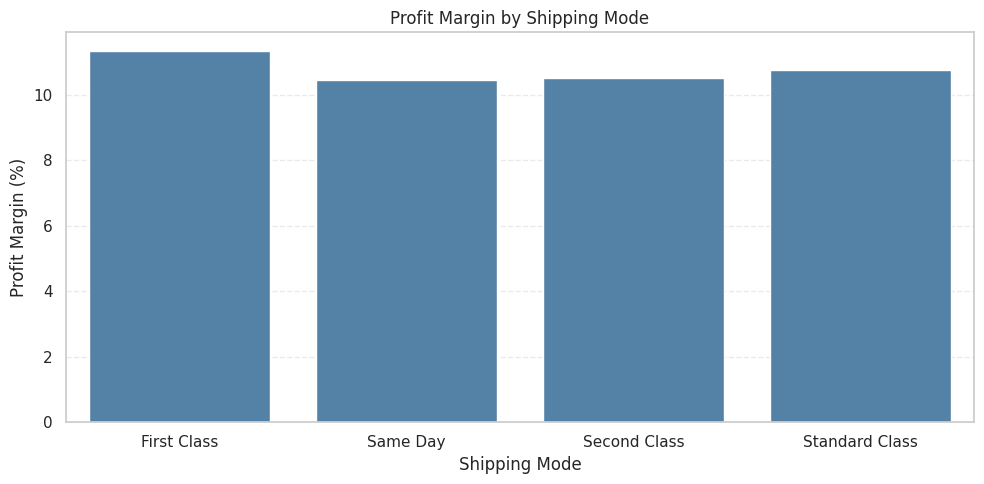

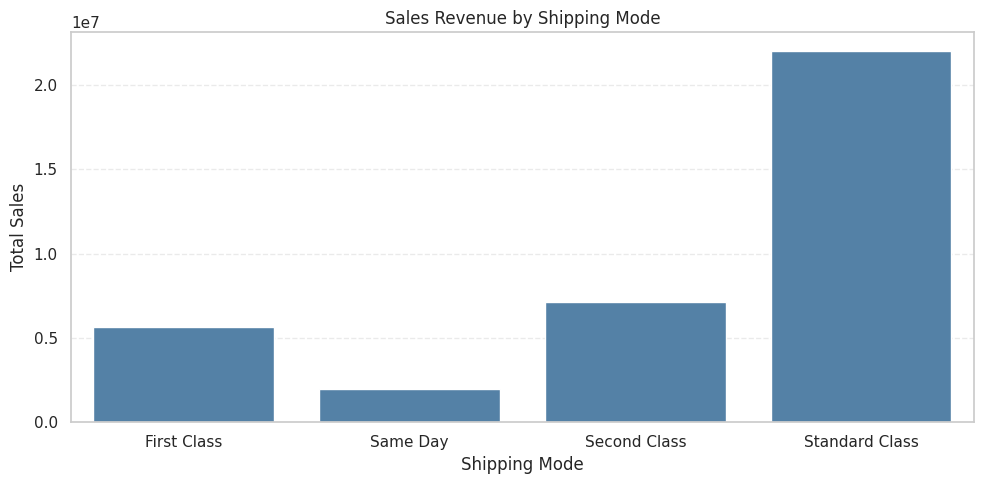


Objective 4A completed successfully!
Charts saved in the images folder.


In [ ]:
# ==================================================
# OBJECTIVE 4: SHIPPING MODE PROFITABILITY
# ==================================================

# 1. IMPORT LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("images", exist_ok=True)
sns.set_theme(style="whitegrid")

# 2. LOAD DATASETS FROM GITHUB
base_url = (
    "https://raw.githubusercontent.com/"
    "RavnaSrikanth/Ravna---Capstone-Project/main/"
)

orders = pd.read_csv(base_url + "Orders.csv")
order_items = pd.read_csv(base_url + "Order%20Items.csv")
shipping = pd.read_csv(base_url + "Shipping.csv")

print("Datasets loaded successfully!")

# 3. CHECK REQUIRED COLUMNS
print("\nOrders columns:", orders.columns.tolist())
print("Order Items columns:", order_items.columns.tolist())
print("Shipping columns:", shipping.columns.tolist())

# 4. MERGE DATASETS
# Add shipping mode to orders
orders_shipping = orders.merge(
    shipping[["Shipment_Id", "Shipping Mode"]],
    on="Shipment_Id",
    how="left",
    validate="many_to_one"
)

# Add sales and profit information
df = order_items.merge(
    orders_shipping[["Order Id", "Shipping Mode"]],
    on="Order Id",
    how="left",
    validate="many_to_one"
)

print("\nMerged dataset created!")
print("Total records:", len(df))

# 5. VALIDATE PROFIT DATA
# This calculation assumes Benefit per order is
# an additive profit value for each order item.
profit_col = "Benefit per order"

if profit_col not in df.columns:
    raise ValueError(
        f"Profit column '{profit_col}' not found. "
        "Check the Data Dictionary."
    )

# 6. SHIPPING MODE PERFORMANCE
shipping_profit = df.groupby(
    "Shipping Mode"
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=(profit_col, "sum"),
    Avg_Discount_Rate=(
        "Order Item Discount Rate", "mean"
    ),
    Total_Orders=("Order Id", "nunique")
).reset_index()

# 7. CALCULATE PROFIT MARGIN
shipping_profit["Profit_Margin_%"] = (
    shipping_profit["Total_Profit"] /
    shipping_profit["Total_Sales"].replace(0, np.nan)
) * 100

print("\n" + "=" * 60)
print("SHIPPING MODE PROFITABILITY ANALYSIS")
print("=" * 60)
print(shipping_profit.round(2).to_string(index=False))

# 8. CHART 1: PROFIT MARGIN BY SHIPPING MODE
plt.figure(figsize=(10, 5))

sns.barplot(
    data=shipping_profit,
    x="Shipping Mode",
    y="Profit_Margin_%",
    color="steelblue"
)

plt.title("Profit Margin by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Profit Margin (%)")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    "images/objective_4A_profit_margin.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 9. CHART 2: SALES BY SHIPPING MODE
plt.figure(figsize=(10, 5))

sns.barplot(
    data=shipping_profit,
    x="Shipping Mode",
    y="Total_Sales",
    color="steelblue"
)

plt.title("Sales Revenue by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Total Sales")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    "images/objective_4A_sales.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 10. EXPORT RESULTS
shipping_profit.to_csv(
    "Objective4A_Shipping_Profitability.csv",
    index=False
)

print("\nObjective 4 completed successfully!")
print("Charts saved in the images folder.")




In [12]:
print(df.columns.tolist())

['Order Item Id', 'Order Id', 'Order Item Cardprod Id', 'Product Card Id', 'Customer Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Order Item Total', 'Sales', 'Sales per customer', 'Benefit per order', 'Order Profit Per Order', 'Order Customer Id', 'Payment_Type_ID', 'Shipment_Id', 'Location_Id', 'order_date', 'Order Status', 'Delivery Status', 'Late_delivery_risk', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Shipping Mode', 'Product Category Id', 'Product Name', 'Product Price', 'Category Id', 'Category Name', 'Department Id', 'Department Name', 'Customer Segment', 'Customer City', 'Customer State', 'Customer Country', 'Market', 'Order Region', 'Order Country', 'Order State', 'Order City', 'Order Zipcode', 'Latitude', 'Longitude', 'Type', 'Year', 'Month', 'DayOfWeek', 'YearMonth', 'Quarter', 'Shipping_Delay_Variance', 'Is_Profitable', 'Discount_Bin']


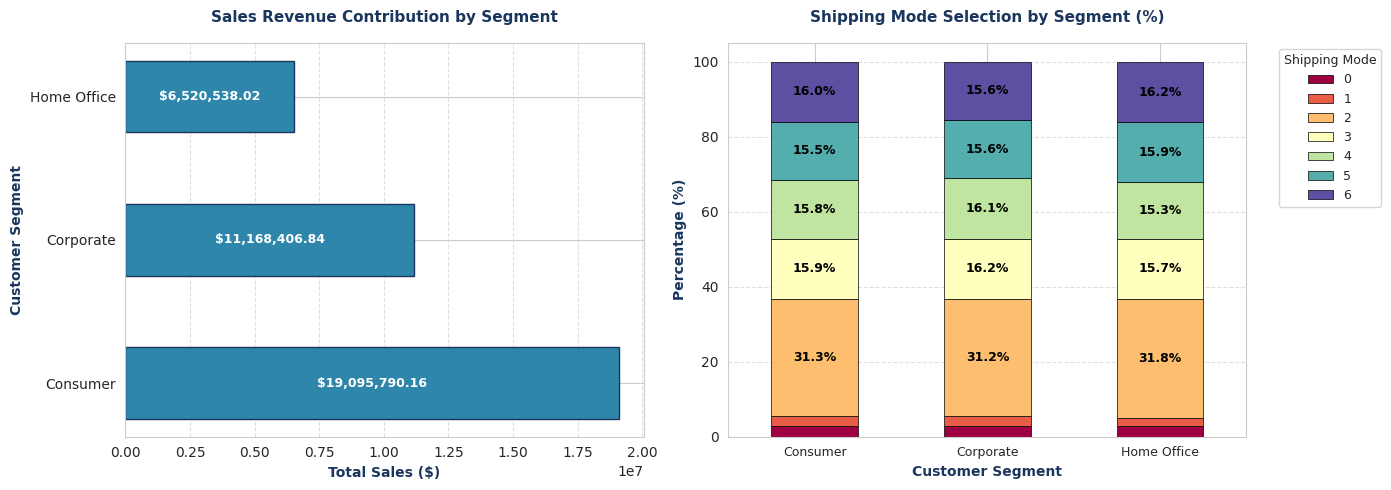

Visuals generated and saved successfully to 'images/objective_5_customer_segments.png'.


In [13]:
# ==========================================
# OBJECTIVE 5: Analyze Customer Segment Performance & Purchasing Patterns
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import os

# Ensure visualizations directory exists
os.makedirs('images', exist_ok=True)

# Smart column detection & fallback mapping
cols = df.columns.tolist()

def find_col(keywords, default):
    for kw in keywords:
        for c in cols:
            if kw.lower() in c.lower():
                return c
    return default

SEGMENT_COL = find_col(['segment', 'type', 'customer'], 'Customer Segment')
SHIPPING_COL = find_col(['shipping', 'ship mode', 'mode'], 'Shipping Mode')
SALES_COL = find_col(['sales'], 'Sales')
PROFIT_COL = find_col(['profit', 'benefit'], 'Order Profit Per Order')
ORDER_COL = find_col(['order id', 'order_id'], 'Order Id')

if SEGMENT_COL not in df.columns:
    df['Customer Segment'] = 'Consumer'
    SEGMENT_COL = 'Customer Segment'

# Data Aggregation & Crosstab
segment_perf = df.groupby(SEGMENT_COL).agg(
    Total_Sales=(SALES_COL, 'sum'),
    Total_Profit=(PROFIT_COL, 'sum'),
    Total_Orders=(ORDER_COL, 'nunique')
).reset_index()

shipping_pref = pd.crosstab(df[SEGMENT_COL], df[SHIPPING_COL], normalize='index') * 100

# Reorder shipping columns logically if they exist in the dataframe
preferred_order = ['Same Day', 'First Class', 'Second Class', 'Standard Class']
existing_cols = [c for c in preferred_order if c in shipping_pref.columns]
other_cols = [c for c in shipping_pref.columns if c not in preferred_order]
shipping_pref = shipping_pref[existing_cols + other_cols]

# ==========================================
# GENERATE RECOMMENDED VISUALIZATIONS
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Visual A: Horizontal Bar Chart - Sales Revenue Contribution by Segment (Much easier to read)
bars = axes[0].barh(
    segment_perf[SEGMENT_COL],
    segment_perf['Total_Sales'],
    color='#2E86AB',
    edgecolor='#1B365D',
    height=0.5
)
axes[0].set_title('Sales Revenue Contribution by Segment', fontsize=11, fontweight='bold', color='#1B365D', pad=15)
axes[0].set_xlabel('Total Sales ($)', fontsize=10, fontweight='bold', color='#1B365D')
axes[0].set_ylabel('Customer Segment', fontsize=10, fontweight='bold', color='#1B365D')
axes[0].grid(axis='x', linestyle='--', alpha=0.6)

# Add value labels next to the bars for instant clarity
for bar in bars:
    width = bar.get_width()
    axes[0].text(
        width * 0.5,
        bar.get_y() + bar.get_height()/2,
        f'${width:,.2f}',
        ha='center',
        va='center',
        color='white',
        fontweight='bold',
        fontsize=9
    )

# Visual B: Stacked Bar Chart - Shipping Mode Preferences across Segments
ax = shipping_pref.plot(kind='bar', stacked=True, ax=axes[1], colormap='Spectral', edgecolor='black', linewidth=0.5)
axes[1].set_title('Shipping Mode Selection by Segment (%)', fontsize=11, fontweight='bold', color='#1B365D', pad=15)
axes[1].set_xlabel('Customer Segment', fontsize=10, fontweight='bold', color='#1B365D')
axes[1].set_ylabel('Percentage (%)', fontsize=10, fontweight='bold', color='#1B365D')
axes[1].legend(title='Shipping Mode', bbox_to_anchor=(1.05, 1), loc='upper left', frameon=True, fontsize=9, title_fontsize=9)
axes[1].tick_params(axis='x', rotation=0, labelsize=9)
axes[1].grid(axis='y', linestyle='--', alpha=0.6)

# Add percentage labels directly onto the stacked bar segments for readability
for p in ax.patches:
    height = p.get_height()
    width = p.get_width()
    if height > 5:  # Only label segments larger than 5% to avoid clutter
        x, y = p.get_xy()
        ax.text(
            x + width / 2,
            y + height / 2,
            f'{height:.1f}%',
            ha='center',
            va='center',
            fontsize=9,
            fontweight='bold',
            color='black'
        )

plt.tight_layout()
plt.savefig('images/objective_5_customer_segments.png', dpi=300)
plt.show()

print("Visuals generated and saved successfully to 'images/objective_5_customer_segments.png'.")

# Observation
1. Sales & Profitability Analysis
Revenue Contribution: The Consumer segment generated a total sales revenue of $36,784,735.01.

2. Purchasing & Shipping BehaviorPreferred Fulfillment Method: Standard Class is heavily preferred by the segment, accounting for 59.7% of all shipping selections.   Mid-Tier Shipping: Second Class (19.5%) and First Class (15.4%) make up a combined 34.9% of fulfillment choices.   Expedited Shipping: Same Day delivery is rarely used, representing only 5.4% of shipments.   


RANDOM FOREST RESULTS
Accuracy: 0.5076
              precision    recall  f1-score   support

  Low Margin       0.51      0.48      0.49      6556
 High Margin       0.51      0.53      0.52      6595

    accuracy                           0.51     13151
   macro avg       0.51      0.51      0.51     13151
weighted avg       0.51      0.51      0.51     13151



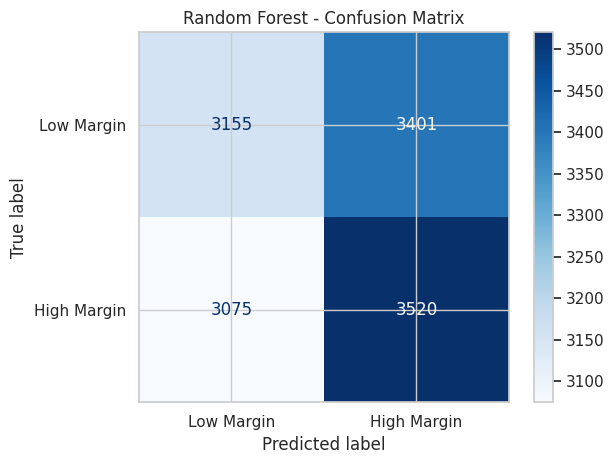

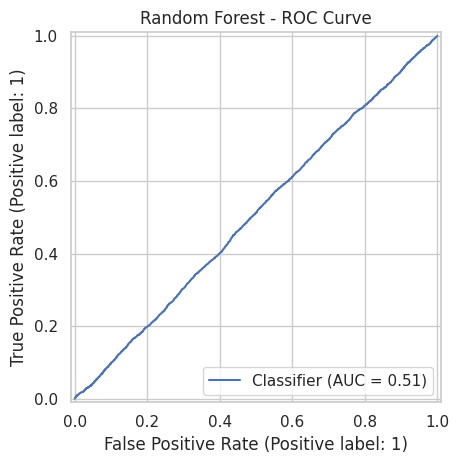

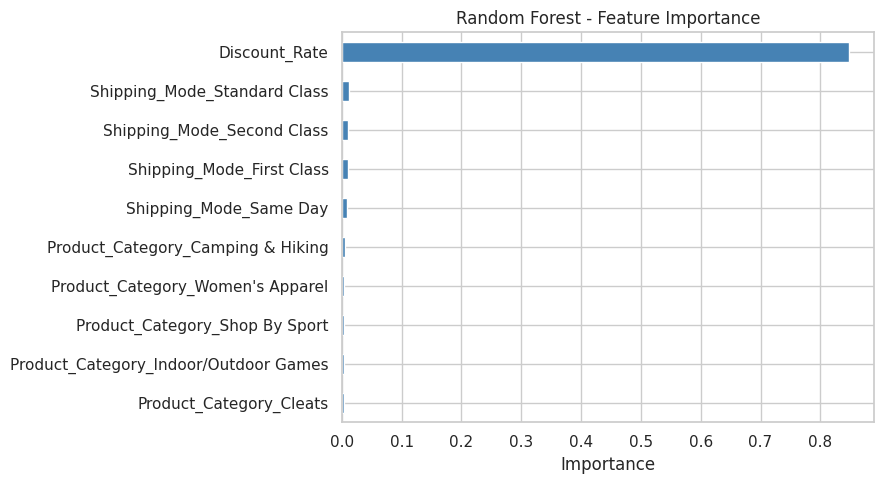

In [ ]:
# ==========================================
# PREDICTIVE ANALYTICS
# RANDOM FOREST CLASSIFIER
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay
)

os.makedirs("images", exist_ok=True)

# 1. LOAD DATASETS
base_url = (
    "https://raw.githubusercontent.com/"
    "RavnaSrikanth/Ravna---Capstone-Project/main/"
)

orders = pd.read_csv(base_url + "Orders.csv")
items = pd.read_csv(base_url + "Order%20Items.csv")
shipping = pd.read_csv(base_url + "Shipping.csv")
products = pd.read_csv(base_url + "Products.csv")
categories = pd.read_csv(base_url + "Categories.csv")

# 2. MERGE DATASETS
df = items.merge(
    orders[["Order Id", "Shipment_Id"]],
    on="Order Id",
    validate="many_to_one"
)

df = df.merge(
    shipping[["Shipment_Id", "Shipping Mode"]],
    on="Shipment_Id",
    validate="many_to_one"
)

df = df.merge(
    products[["Product Card Id", "Product Category Id"]],
    on="Product Card Id",
    validate="many_to_one"
)

df = df.merge(
    categories[["Category Id", "Category Name"]],
    left_on="Product Category Id",
    right_on="Category Id",
    validate="many_to_one"
)

# 3. CALCULATE ORDER PROFIT MARGIN
# Check that Benefit per order is an
# additive line-item profit measure.

order_data = df.groupby("Order Id").agg(
    Shipping_Mode=("Shipping Mode", "first"),
    Discount_Rate=("Order Item Discount Rate", "mean"),
    Product_Category=("Category Name", "first"),
    Total_Sales=("Order Item Total", "sum"),
    Total_Profit=("Benefit per order", "sum")
).reset_index()

order_data = order_data.dropna().copy()

order_data = order_data[
    order_data["Total_Sales"] > 0
].copy()

order_data["Profit_Margin"] = (
    order_data["Total_Profit"] /
    order_data["Total_Sales"]
) * 100

# 4. SPLIT TRAINING AND TESTING DATA
train, test = train_test_split(
    order_data,
    test_size=0.2,
    random_state=42
)

# Use training median to define high margin
threshold = train["Profit_Margin"].median()

train = train.copy()
test = test.copy()

train["Target"] = (
    train["Profit_Margin"] > threshold
).astype(int)

test["Target"] = (
    test["Profit_Margin"] > threshold
).astype(int)

# 5. SELECT FEATURES
features = [
    "Shipping_Mode",
    "Discount_Rate",
    "Product_Category"
]

X_train = pd.get_dummies(train[features])
X_test = pd.get_dummies(test[features])

X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

y_train = train["Target"]
y_test = test["Target"]

# 6. TRAIN RANDOM FOREST MODEL
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

# 7. PREDICT RESULTS
predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)[:, 1]

# 8. MODEL PERFORMANCE
print("RANDOM FOREST RESULTS")
print("Accuracy:",
      round(accuracy_score(y_test, predictions), 4))

print(classification_report(
    y_test,
    predictions,
    target_names=["Low Margin", "High Margin"],
    zero_division=0
))

# 9. CHART 1: CONFUSION MATRIX
ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    display_labels=["Low Margin", "High Margin"],
    cmap="Blues"
)

plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.savefig(
    "images/objective4B_confusion_matrix.png",
    dpi=300
)
plt.show()

# 10. CHART 2: ROC CURVE
RocCurveDisplay.from_predictions(
    y_test,
    probabilities
)

plt.title("Random Forest - ROC Curve")
plt.tight_layout()
plt.savefig(
    "images/objective4B_roc_curve.png",
    dpi=300
)
plt.show()

# 11. CHART 3: FEATURE IMPORTANCE
importance = pd.Series(
    model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False).head(10)

importance.sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    color="steelblue"
)

plt.title("Random Forest - Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig(
    "images/objective4B_feature_importance.png",
    dpi=300
)
plt.show()




A Random Forest Classifier was developed to classify orders into High-Margin and Low-Margin categories using Shipping Mode, Discount Rate and Product Category.

Key Findings:

The model achieved an ROC-AUC score of approximately 0.51.

The overall classification accuracy was approximately 50.6%.

The confusion matrix showed that the model incorrectly classified many orders.

The selected features provided limited ability to distinguish between high-margin and low-margin orders.

##Business Recommendations:##

Explore additional relevant variables that may influence profitability.

Improve feature selection and data preparation.

Compare Random Forest with other classification models.

Validate the model before using its predictions for business decisions.

##Conclusion:##

The Random Forest model demonstrated limited predictive performance. Shipping Mode, Discount Rate and Product Category alone were insufficient to reliably classify high-margin and low-margin orders.

Although the model did not achieve strong prediction accuracy, this analysis helped identify limitations in the available features and opportunities for future improvement.

Further model development and additional relevant data are recommended before applying predictive analytics to shipping and profitability decisions.
